# NLP HW3: Multi-Task Learning with BERT
## Task: Semantic Relatedness & Entailment Judgment

This notebook implements a multi-task learning model using BERT for:
1. **Task 1 (Regression)**: Predicting semantic relatedness scores
2. **Task 2 (Classification)**: Predicting entailment judgments

### Dataset
- **SemEval 2014 Task 1**: Sentence pairs with relatedness scores and entailment labels
- **Splits**: Train, Validation, Test

### Model Architecture
- Base: BERT (bert-base-uncased)
- Two task-specific heads (regression + classification)
- Shared BERT encoder for both tasks

In [14]:
import os
from transformers import BertTokenizer, BertModel
from datasets import load_dataset
from evaluate import load
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from tqdm import tqdm
import numpy as np
import random

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"Available GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Using device: cuda
CUDA device: NVIDIA RTX PRO 6000 Blackwell Server Edition
Available GPU memory: 101.97 GB


In [15]:
# Some Chinese punctuations will be tokenized as [UNK], so we replace them with English ones
token_replacement = [
    ["：" , ":"],
    ["，" , ","],
    ["“" , "\""],
    ["”" , "\""],
    ["？" , "?"],
    ["……" , "..."],
    ["！" , "!"]
]

In [16]:

tokenizer = BertTokenizer.from_pretrained("google-bert/bert-base-uncased", cache_dir="./cache/")

In [17]:
class SemevalDataset(Dataset):
    def __init__(self, split="train") -> None:
        super().__init__()
        assert split in ["train", "validation", "test"]
        # Load dataset using the Parquet export instead of script
        self.data = load_dataset(
            "sem_eval_2014_task_1", split=split, cache_dir="./cache/", revision="refs/convert/parquet"
        ).to_list()

    def __getitem__(self, index):
        d = self.data[index]
        # Replace Chinese punctuations with English ones
        for k in ["premise", "hypothesis"]:
            for tok in token_replacement:
                d[k] = d[k].replace(tok[0], tok[1])
        return d

    def __len__(self):
        return len(self.data)

data_sample = SemevalDataset(split="train").data[:3]
print(f"Dataset example: \n{data_sample[0]} \n{data_sample[1]} \n{data_sample[2]}")

Dataset example: 
{'sentence_pair_id': 1, 'premise': 'A group of kids is playing in a yard and an old man is standing in the background', 'hypothesis': 'A group of boys in a yard is playing and a man is standing in the background', 'relatedness_score': 4.5, 'entailment_judgment': 0} 
{'sentence_pair_id': 2, 'premise': 'A group of children is playing in the house and there is no man standing in the background', 'hypothesis': 'A group of kids is playing in a yard and an old man is standing in the background', 'relatedness_score': 3.200000047683716, 'entailment_judgment': 0} 
{'sentence_pair_id': 3, 'premise': 'The young boys are playing outdoors and the man is smiling nearby', 'hypothesis': 'The kids are playing outdoors near a man with a smile', 'relatedness_score': 4.699999809265137, 'entailment_judgment': 1}


In [18]:
# Define the hyperparameters
# You can modify these values if needed
lr = 3e-5
epochs = 3
train_batch_size = 8
validation_batch_size = 8
test_batch_size = 8

In [19]:
# TODO1: Create batched data for DataLoader
# `collate_fn` is a function that defines how the data batch should be packed.
# This function will be called in the DataLoader to pack the data batch.

def collate_fn(batch):
    # TODO1-1: Implement the collate_fn function
    # Extract premises and hypotheses from the batch
    premises = [item['premise'] for item in batch]
    hypotheses = [item['hypothesis'] for item in batch]
    relatedness_scores = torch.tensor([item['relatedness_score'] for item in batch], dtype=torch.float32)
    entailment_judgments = torch.tensor([item['entailment_judgment'] for item in batch], dtype=torch.long)
    
    # Ensure entailment judgments are in valid range [0, 1]
    entailment_judgments = torch.clamp(entailment_judgments, 0, 1)
    
    # Tokenize premise and hypothesis pairs
    encoded = tokenizer(
        premises, 
        hypotheses, 
        padding=True, 
        truncation=True, 
        return_tensors='pt',
        max_length=128
    )
    
    return {
        'input_ids': encoded['input_ids'],
        'attention_mask': encoded['attention_mask'],
        'token_type_ids': encoded['token_type_ids'],
        'relatedness_score': relatedness_scores,
        'entailment_judgment': entailment_judgments
    }

# TODO1-2: Define your DataLoader
dl_train = DataLoader(
    SemevalDataset(split="train"), 
    batch_size=train_batch_size, 
    shuffle=True, 
    collate_fn=collate_fn
)
dl_validation = DataLoader(
    SemevalDataset(split="validation"), 
    batch_size=validation_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn
)
dl_test = DataLoader(
    SemevalDataset(split="test"), 
    batch_size=test_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn
)

print(f"Train batches: {len(dl_train)}, Validation batches: {len(dl_validation)}, Test batches: {len(dl_test)}")

Train batches: 563, Validation batches: 63, Test batches: 616


In [20]:
# TODO2: Construct your model
class MultiLabelModel(torch.nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Load BERT base model
        self.bert = BertModel.from_pretrained("google-bert/bert-base-uncased", cache_dir="./cache/")
        
        # Get hidden size from BERT config (768 for bert-base)
        hidden_size = self.bert.config.hidden_size
        
        # Task 1: Regression head for relatedness score (continuous value)
        self.regression_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 1)
        )
        
        # Task 2: Classification head for entailment judgment (binary classification)
        self.classification_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 2)  # 2 classes: 0 or 1
        )
    
    def forward(self, input_ids, attention_mask, token_type_ids, **kwargs):
        # Forward pass through BERT
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        # Use [CLS] token representation (first token)
        cls_output = outputs.last_hidden_state[:, 0, :]  # Shape: (batch_size, hidden_size)
        
        # Task 1: Regression for relatedness score
        relatedness_pred = self.regression_head(cls_output).squeeze(-1)  # Shape: (batch_size,)
        
        # Task 2: Classification for entailment judgment
        entailment_logits = self.classification_head(cls_output)  # Shape: (batch_size, 2)
        
        return {
            'relatedness_pred': relatedness_pred,
            'entailment_logits': entailment_logits
        }

In [21]:
# TODO3: Define your optimizer and loss function

model = MultiLabelModel().to(device)

# Print model parameter count
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# TODO3-1: Define your Optimizer
optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)

# TODO3-2: Define your loss functions (you should have two)
# Loss function for regression task (relatedness score)
regression_loss_fn = torch.nn.MSELoss()

# Loss function for classification task (entailment judgment)
classification_loss_fn = torch.nn.CrossEntropyLoss()

# scoring functions
psr = load("pearsonr")
acc = load("accuracy")

Total parameters: 109,876,739
Trainable parameters: 109,876,739


In [22]:
# Create saved_models directory if it doesn't exist
os.makedirs('./saved_models', exist_ok=True)

best_score = 0.0
training_history = {
    'train_loss': [],
    'val_pearson': [],
    'val_accuracy': []
}

for ep in range(epochs):
    pbar = tqdm(dl_train)
    pbar.set_description(f"Training epoch [{ep+1}/{epochs}]")
    model.train()
    # TODO4: Write the training loop
    total_train_loss = 0
    for batch in pbar:
        # Clear gradient
        optimizer.zero_grad()
        
        # Move batch to device
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        # Compute loss for both tasks
        regression_loss = regression_loss_fn(outputs['relatedness_pred'], relatedness_score)
        classification_loss = classification_loss_fn(outputs['entailment_logits'], entailment_judgment)
        
        # Combined loss
        loss = regression_loss + classification_loss
        
        # Back-propagation
        loss.backward()
        
        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        # Model optimization
        optimizer.step()
        
        total_train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = total_train_loss / len(dl_train)
    training_history['train_loss'].append(avg_train_loss)
    print(f"Epoch {ep+1}/{epochs} - Average Training Loss: {avg_train_loss:.4f}")

    pbar = tqdm(dl_validation)
    pbar.set_description(f"Validation epoch [{ep+1}/{epochs}]")
    model.eval()
    # TODO5: Write the evaluation loop
    all_relatedness_preds = []
    all_relatedness_targets = []
    all_entailment_preds = []
    all_entailment_targets = []
    
    with torch.no_grad():
        for batch in pbar:
            # Move batch to device
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            token_type_ids = batch['token_type_ids'].to(device)
            relatedness_score = batch['relatedness_score'].to(device)
            entailment_judgment = batch['entailment_judgment'].to(device)
            
            # Forward pass
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )
            
            # Collect predictions and targets for regression task
            all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
            all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
            
            # Collect predictions and targets for classification task
            entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
            all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
            all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())
    
    # Evaluate your model
    # Output all the evaluation scores (PearsonCorr, Accuracy)
    pearson_corr = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
    accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']
    
    training_history['val_pearson'].append(pearson_corr)
    training_history['val_accuracy'].append(accuracy)
    
    print(f"Epoch {ep+1}/{epochs} - Validation Pearson Correlation: {pearson_corr:.4f}, Accuracy: {accuracy:.4f}")
    
    # Save best model based on combined score
    combined_score = pearson_corr + accuracy
    if combined_score > best_score:
        best_score = combined_score
        torch.save(model.state_dict(), f'./saved_models/best_model.ckpt')
        print(f"✓ New best model saved with combined score: {best_score:.4f}")

print("\n" + "="*50)
print("Training Summary")
print("="*50)
for ep in range(epochs):
    print(f"Epoch {ep+1}: Train Loss={training_history['train_loss'][ep]:.4f}, "
          f"Val Pearson={training_history['val_pearson'][ep]:.4f}, "
          f"Val Accuracy={training_history['val_accuracy'][ep]:.4f}")
print("="*50)

Training epoch [1/3]: 100%|██████████| 563/563 [00:25<00:00, 22.42it/s, loss=0.9049]


Epoch 1/3 - Average Training Loss: 1.0326


Validation epoch [1/3]: 100%|██████████| 63/63 [00:00<00:00, 85.85it/s]



Epoch 1/3 - Validation Pearson Correlation: 0.8673, Accuracy: 0.8580
✓ New best model saved with combined score: 1.7253
✓ New best model saved with combined score: 1.7253


Training epoch [2/3]: 100%|██████████| 563/563 [00:26<00:00, 21.48it/s, loss=0.7262]


...

Epoch 2/3 - Validation Pearson Correlation: 0.8650, Accuracy: 0.8380


Training epoch [3/3]: 100%|██████████| 563/563 [00:25<00:00, 21.93it/s, loss=0.4055]


Epoch 3/3 - Average Training Loss: 0.3941


Validation epoch [3/3]: 100%|██████████| 63/63 [00:00<00:00, 142.48it/s]

Epoch 3/3 - Validation Pearson Correlation: 0.8622, Accuracy: 0.8440

Training Summary
Epoch 1: Train Loss=1.0326, Val Pearson=0.8673, Val Accuracy=0.8580
Epoch 2: Train Loss=0.5353, Val Pearson=0.8650, Val Accuracy=0.8380
Epoch 3: Train Loss=0.3941, Val Pearson=0.8622, Val Accuracy=0.8440


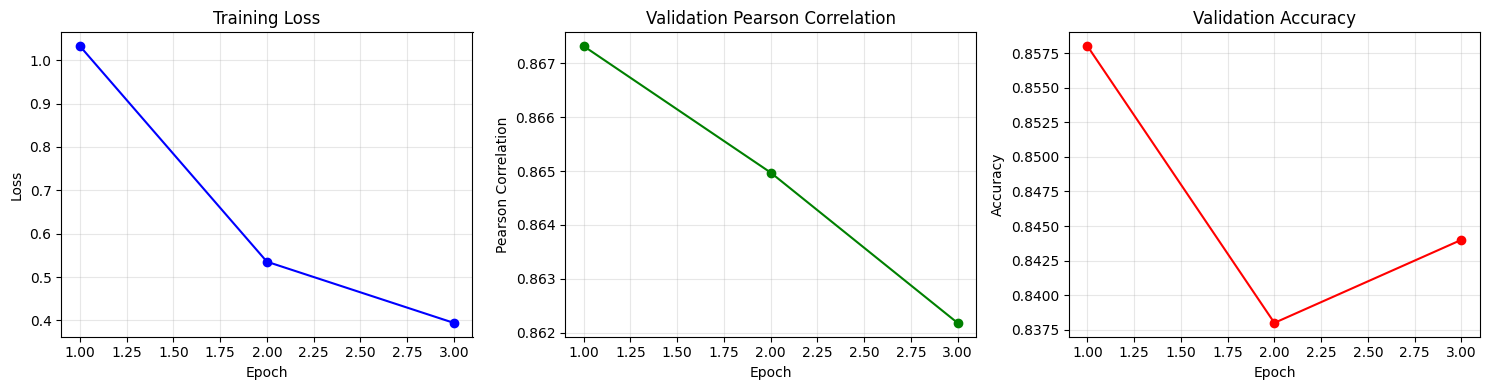

In [25]:
# Optional: Visualize training history
try:
    import matplotlib.pyplot as plt
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Plot training loss
    axes[0].plot(range(1, epochs+1), training_history['train_loss'], marker='o', color='blue')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Loss')
    axes[0].grid(True, alpha=0.3)
    
    # Plot validation Pearson correlation
    axes[1].plot(range(1, epochs+1), training_history['val_pearson'], marker='o', color='green')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Pearson Correlation')
    axes[1].set_title('Validation Pearson Correlation')
    axes[1].grid(True, alpha=0.3)
    
    # Plot validation accuracy
    axes[2].plot(range(1, epochs+1), training_history['val_accuracy'], marker='o', color='red')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Accuracy')
    axes[2].set_title('Validation Accuracy')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib not installed. Install with: pip install matplotlib")

In [24]:
# Load the model
model = MultiLabelModel().to(device)
model.load_state_dict(torch.load(f"./saved_models/best_model.ckpt", weights_only=True))

# Test Loop
pbar = tqdm(dl_test, desc="Test")
model.eval()

# TODO6: Write the test loop
all_relatedness_preds = []
all_relatedness_targets = []
all_entailment_preds = []
all_entailment_targets = []

with torch.no_grad():
    for batch in pbar:
        # Move batch to device
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        # Collect predictions and targets for regression task
        all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
        all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
        
        # Collect predictions and targets for classification task
        entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
        all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
        all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())

# Compute test metrics
test_pearson_corr = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
test_accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']

print(f"\n{'='*50}")
print(f"Test Results:")
print(f"{'='*50}")
print(f"Pearson Correlation: {test_pearson_corr:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Combined Score: {test_pearson_corr + test_accuracy:.4f}")
print(f"{'='*50}")

Test: 100%|██████████| 616/616 [00:04<00:00, 152.08it/s]


Test Results:
Pearson Correlation: 0.8612
Accuracy: 0.8687
Combined Score: 1.7299
